# 04 Clustering and label-free selection

**Owners:** Ayesha (k-means), Fatema (hierarchical). **Runs in:** about 30 minutes if recomputed; the cached sweep loads instantly.

**Rule:** on the selection set (train + val, 2,040 images), *without labels*, try every combination of

- method: k-means (k-means++, 10 restarts, 5 seeds), Ward, average linkage with cosine distance
- PCA: none, or keep 95% of the variance
- number of groups k: 10, 20, ..., 200

and keep, for each representation, the one with the highest **silhouette score**. Silhouette is computed per image as (b - a) / max(a, b), where a is the average distance to its own group and b to the nearest other group. It is then averaged over images: near 1 means tight, well-separated groups, near 0 means overlapping groups.

The choice is written to `results/selection_frozen.json` **before** any label is read. The evaluation code refuses to load labels until that file exists.

In [7]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from p22 import config, data
pd.set_option("display.precision", 3)
from p22 import selection

## 1. The sweep
`RECOMPUTE = True` re-runs it (it never touches labels); `select_settings.py` does the same and also freezes.

In [8]:
RECOMPUTE = False
if RECOMPUTE:
    blocks = {f.stem: np.load(f) for f in config.FEATURES_DIR.glob("*.npy")}
    sweep, choices = selection.run(blocks, data.load_split())
else:
    sweep = pd.read_csv(config.RESULTS_DIR / "selection_sweep.csv")
sweep.head()

,representation,method,pca,pca_dims,k,clusters_found,silhouette,silhouette_sd,davies_bouldin,largest_cluster_share,seed_stability_ari
0,mean_colour,kmeans,False,NaN,10,10,0.268,0.007,1.056,0.186,0.793
1,mean_colour,kmeans,False,NaN,20,20,0.249,0.001,1.046,0.099,0.544
2,mean_colour,kmeans,False,NaN,30,30,0.245,0.003,1.050,0.071,0.523
3,mean_colour,kmeans,False,NaN,40,40,0.245,0.003,1.031,0.060,0.599
4,mean_colour,kmeans,False,NaN,50,50,0.246,0.003,1.038,0.044,0.544


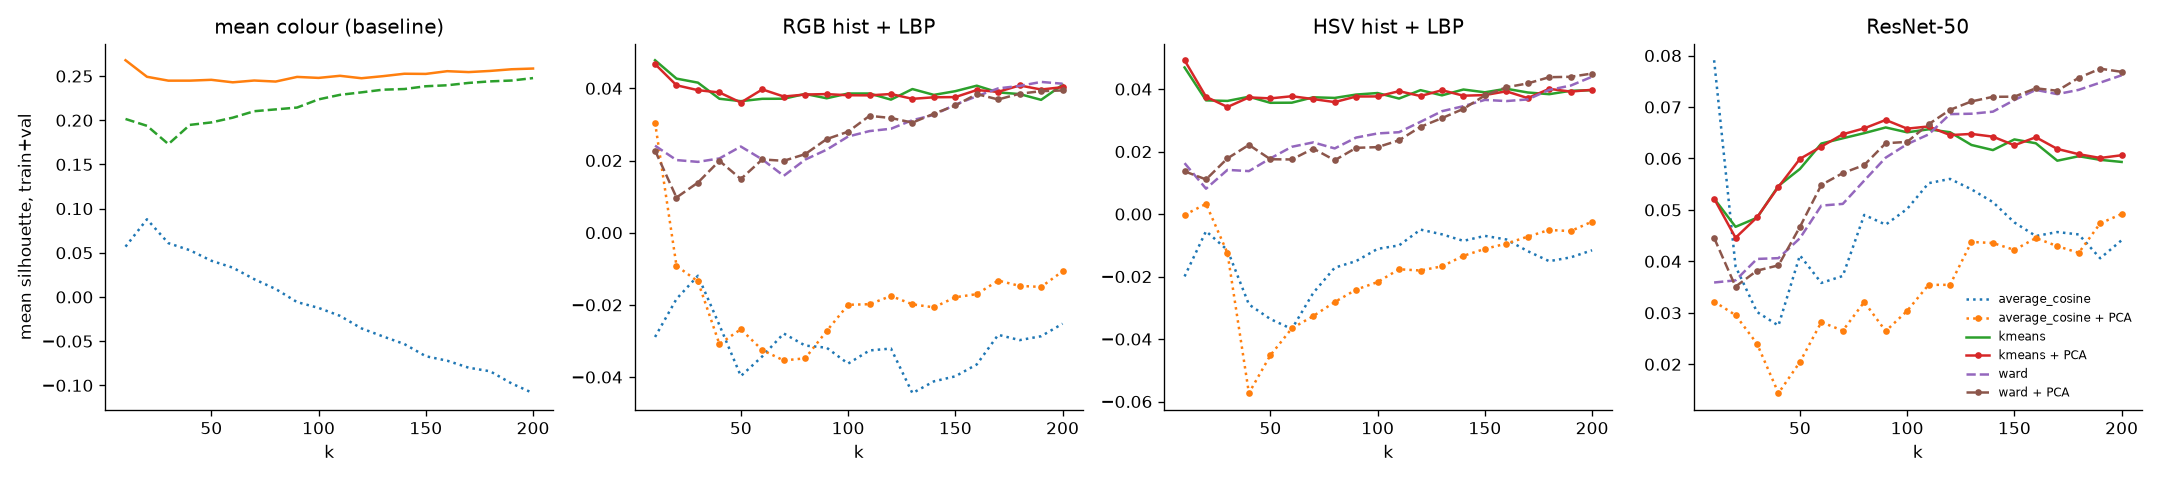

In [9]:
display(Image(config.FIGURES_DIR / "selection_silhouette.png"))

## 2. What was chosen

In [10]:
frozen = json.loads(config.FROZEN_SELECTION.read_text())
print("frozen at", frozen["frozen_at"])
pd.DataFrame(frozen["choices"]).T

frozen at 2026-11-08T10:37:36+00:00


,method,pca,k,silhouette,davies_bouldin
mean_colour,kmeans,False,10,0.27,1.054
hand_rgb_lbp,kmeans,False,10,0.049,2.709
hand_hsv_lbp,kmeans,True,10,0.047,2.929
resnet50,average_cosine,False,10,0.079,2.047


### Reading this honestly
- Silhouette picked **k = 10 for every representation**, the bottom of the grid. Silhouette tends to prefer a few broad groups.
- For ResNet-50 it picked **average-cosine linkage**, which puts 87% of the selection images in one group. The few small groups left are very tight, so the average silhouette looks good. The `largest_cluster_share` column shows this.

So we also saved the best silhouette **per method** (`selection_per_method.json`, DECISIONS.md D12). It is still label-free, and it was written before any test score was printed (the timing is in DECISIONS.md, D12).

## 3. Stability across k-means seeds
The mean adjusted Rand index between the 5 seed runs (1 = identical groupings). Small k is more stable; at larger k the seeds disagree more.

In [ ]:
km = sweep[(sweep.method == "kmeans") & (~sweep.pca)]
km.pivot(index="k", columns="representation", values="seed_stability_ari").loc[[10, 50, 100, 150, 200]]

representation,hand_hsv_lbp,hand_rgb_lbp,mean_colour,resnet50
k,,,,
10,0.517,0.621,0.840,0.755
50,0.297,0.319,0.525,0.478
100,0.282,0.266,0.497,0.429
150,0.255,0.251,0.494,0.437
200,0.260,0.245,0.529,0.417


## 4. The label lock
The function below is the only one that reads species labels. Before the freeze it raised `PermissionError`; every successful call is logged with the frozen file's SHA-256.

In [ ]:
print((config.RESULTS_DIR / "label_access.log").read_text())

2026-10-19T09:57:19+00:00	selection_frozen.json sha256=23139ae1610be2e9a076a665f7840fdaac8e2afab7ca89f29b16afe65185eee4	final test evaluation
2026-10-19T11:50:02+00:00	selection_frozen.json sha256=23139ae1610be2e9a076a665f7840fdaac8e2afab7ca89f29b16afe65185eee4	per-method choices (D12)
2026-10-19T11:52:57+00:00	selection_frozen.json sha256=23139ae1610be2e9a076a665f7840fdaac8e2afab7ca89f29b16afe65185eee4	analysis of the locked test run
2026-10-19T11:53:30+00:00	selection_frozen.json sha256=23139ae1610be2e9a076a665f7840fdaac8e2afab7ca89f29b16afe65185eee4	analysis of the locked test run
2026-10-19T11:54:20+00:00	selection_frozen.json sha256=23139ae1610be2e9a076a665f7840fdaac8e2afab7ca89f29b16afe65185eee4	analysis of the locked test run

